# 09 · Red Neuronal Convolucional (CNN) con CIFAR-10
**Curso ITEC · C-DAC Noida — Programa Especializado en IA**

En este cuaderno comparamos una **red neuronal normal (ANN)** contra una **red convolucional (CNN)**
clasificando imágenes a color del dataset **CIFAR-10** (10 tipos de objetos).
La idea es ver, con las mismas fotos, por qué la CNN es muy superior para imágenes.

Todo corre en Colab sin subir nada: el dataset ya viene dentro de Keras.

### 1. Instalar e importar las herramientas
TensorFlow es el motor de deep learning; Keras es la interfaz amigable encima de él.

In [2]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


### 2. Cargar el dataset CIFAR-10
Son **60.000 imágenes a color de 32×32 píxeles** en 10 clases.
`load_data()` las trae ya divididas en entrenamiento (50.000) y prueba (10.000).

In [3]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()
print('X_train:', X_train.shape)   # (50000, 32, 32, 3) -> 50000 fotos de 32x32 a color (RGB)
print('X_test :', X_test.shape)

X_train: (50000, 32, 32, 3)
X_test : (10000, 32, 32, 3)


Las etiquetas vienen como columna (2D). Para clasificar nos basta una lista (1D), así que las aplanamos.

In [4]:
y_train = y_train.reshape(-1,)
y_test  = y_test.reshape(-1,)
clases = ['avión','auto','pájaro','gato','ciervo','perro','rana','caballo','barco','camión']
print(y_train[:5])

[6 9 9 4 1]


### 3. Ver algunas imágenes
Así confirmamos qué contiene el dataset.

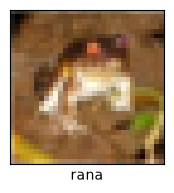

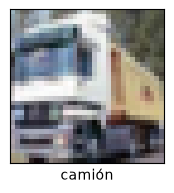

In [5]:
def ver(X, y, i):
    plt.figure(figsize=(2,2))
    plt.imshow(X[i])
    plt.xlabel(clases[y[i]])
    plt.xticks([]); plt.yticks([])
    plt.show()

ver(X_train, y_train, 0)
ver(X_train, y_train, 1)

### 4. Normalizar (muy importante)
Cada píxel va de 0 a 255. Dividimos entre 255 para dejarlo en el rango **0 a 1**.
Con valores pequeños la red aprende de forma más estable y rápida.

In [6]:
X_train = X_train / 255.0
X_test  = X_test  / 255.0

### 5. Primero una red NORMAL (ANN)
Aplana la imagen de una vez y usa solo capas densas. Veremos que le cuesta con fotos a color.

In [7]:
ann = keras.models.Sequential([
    keras.layers.Flatten(input_shape=(32,32,3)),
    keras.layers.Dense(3000, activation='relu'),
    keras.layers.Dense(1000, activation='relu'),
    keras.layers.Dense(10,   activation='softmax')   # 10 clases, softmax = una sola respuesta
])
ann.compile(optimizer='SGD',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
ann.fit(X_train, y_train, epochs=5)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5


   1/1563 ━━━━━━━━━━━━━━━━━━━━ 8:26 324ms/step - accuracy: 0.1250 - loss: 2.5012

   6/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.1198 - loss: 2.4013  

  11/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.1307 - loss: 2.3501

  16/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.1172 - loss: 2.3460

... (1,681 outputs left out)

1552/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4954 - loss: 1.4332

1556/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4956 - loss: 1.4327

1561/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4957 - loss: 1.4327

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.4957 - loss: 1.4325


La ANN termina alrededor del **~49%** de acierto. Flojo para imágenes.

In [8]:
from sklearn.metrics import classification_report
y_pred = ann.predict(X_test)
y_pred_clases = [np.argmax(p) for p in y_pred]
print(classification_report(y_test, y_pred_clases, target_names=clases))

  1/313 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step

 13/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step 

 24/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

 36/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

 48/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

 61/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

... (26 outputs left out)

304/313 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


              precision    recall  f1-score   support

       avión       0.61      0.49      0.54      1000
        auto       0.36      0.82      0.50      1000
      pájaro       0.40      0.28      0.33      1000
        gato       0.42      0.14      0.21      1000
      ciervo       0.39      0.48      0.43      1000
       perro       0.33      0.48      0.39      1000
        rana       0.61      0.39      0.47      1000
     caballo       0.54      0.54      0.54      1000
       barco       0.82      0.25      0.38      1000
      camión       0.41      0.53      0.46      1000

    accuracy                           0.44     10000
   macro avg       0.49      0.44      0.43     10000
weighted avg       0.49      0.44      0.43     10000



### 6. Ahora una CNN (red convolucional)
Aquí está la diferencia:
- **Conv2D**: filtros que detectan formas (bordes, curvas) recorriendo la imagen.
- **MaxPooling2D**: encoge el mapa conservando lo importante (menos cálculo, tolera que el objeto esté movido).
- **Flatten**: aplana a 1D para la parte que decide.
- **Dense + softmax**: la red que clasifica en las 10 clases.

In [9]:
cnn = keras.models.Sequential([
    keras.layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu', input_shape=(32,32,3)),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
cnn.fit(X_train, y_train, epochs=5)

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5


   1/1563 ━━━━━━━━━━━━━━━━━━━━ 10:33 406ms/step - accuracy: 0.0000e+00 - loss: 2.3599

   9/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0868 - loss: 2.3044        

  20/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.1094 - loss: 2.2973 

  31/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.1149 - loss: 2.2898

... (911 outputs left out)

1539/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6943 - loss: 0.8834

1548/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6944 - loss: 0.8834

1557/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6943 - loss: 0.8835

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.6946 - loss: 0.8831


La CNN sube a **~70%** con las mismas fotos: más de 20 puntos por encima de la ANN,
y con menos cálculo porque el pooling reduce el tamaño. **Las CNN son las mejores para imágenes.**

In [10]:
cnn.evaluate(X_test, y_test)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.7812 - loss: 0.7030

 32/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6729 - loss: 0.9419  

 64/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6719 - loss: 0.9457

 95/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6681 - loss: 0.9676

120/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6687 - loss: 0.9664

137/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6720 - loss: 0.9601

... (10 outputs left out)

287/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6721 - loss: 0.9641

309/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6708 - loss: 0.9680

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6701 - loss: 0.9683


[0.9682669043540955, 0.6700999736785889]

### 7. Probar una predicción
Tomamos una imagen de prueba y vemos qué dice la CNN.

  1/313 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step

 14/313 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step  

 39/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 62/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 88/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

114/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

... (6 outputs left out)

274/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

293/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


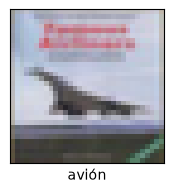

La CNN dice que es: avión


In [11]:
y_pred = cnn.predict(X_test)
y_clases = [np.argmax(p) for p in y_pred]

ver(X_test, y_test, 3)                 # la imagen real
print('La CNN dice que es:', clases[y_clases[3]])

---
### Resumen
| Red | Precisión (5 épocas) |
|-----|----------------------|
| **ANN** (red normal) | ~49% |
| **CNN** (convolucional) | ~70% |

La CNN primero **VE** (convolución + ReLU + pooling) y luego **DECIDE** (flatten + densas).
Por eso gana claramente en imágenes.

*Núcleo IA · curso-itec-c-dac.web.app · C-DAC Noida (ITEC) · 2026*